# Análisis exploratorio de la venta directa

Este análisis estudia la calidad, la evolución y la estacionalidad de las ventas diarias y el reparto de los medios de pago. Utiliza el Gold real localmente, sin modificarlo.

**Confidencialidad:** las tablas y gráficos en euros, fechas concretas, conclusiones y salidas de error pueden revelar información comercial. Antes de publicar el notebook, borra todas las salidas y revisa también el texto. Publica índices, proporciones o tendencias solo dentro de lo autorizado por la bodega: no son anónimos por sí mismos.

El archivo predeterminado es `data/processed/ventas_gold.csv`. Para probar el código con la muestra ficticia, define la variable de entorno `EDA_DATASET` como `data/sample/processed/ventas_gold_sintetico.csv` antes de iniciar el kernel. No se sustituye el Gold real si no existe.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET = Path(os.environ.get("EDA_DATASET", PROJECT_ROOT / "data/processed/ventas_gold.csv"))
if not DATASET.is_absolute():
    DATASET = PROJECT_ROOT / DATASET

required_columns = {"fecha", "tarjeta", "efectivo", "total", "es_festivo"}
ventas = pd.read_csv(DATASET, encoding="utf-8-sig", dtype=str)
missing_columns = required_columns - set(ventas.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing_columns)}")

ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="mixed", errors="coerce")
for column in ["tarjeta", "efectivo", "total"]:
    text = ventas[column].str.replace("€", "", regex=False).str.replace(" ", "", regex=False)
    spanish_format = text.str.contains(",", na=False)
    text.loc[spanish_format] = (
        text.loc[spanish_format].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    )
    ventas[column] = pd.to_numeric(text, errors="coerce")

ventas["es_festivo"] = pd.to_numeric(ventas["es_festivo"], errors="coerce")
ventas = ventas.sort_values("fecha").reset_index(drop=True)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
print("Datos cargados. Revisa los controles de calidad antes de interpretar el análisis.")

Datos cargados. Revisa los controles de calidad antes de interpretar el análisis.


## 1. Calidad y cobertura

La unidad de análisis es una fecha. Se espera un registro diario entre 2022 y 2025, sin duplicados, con importes numéricos no negativos y `tarjeta + efectivo = total` dentro de una tolerancia de un céntimo. Una fecha ausente no se rellena automáticamente: debe investigarse antes de asumir que corresponde a un cierre.

La tabla siguiente contiene recuentos, no importes; aun así, revisa su contenido antes de compartirla.

In [2]:
expected_dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
amount_columns = ["tarjeta", "efectivo", "total"]
valid_dates = ventas["fecha"].notna()
missing_dates = expected_dates.difference(ventas.loc[valid_dates, "fecha"])
outside_period = valid_dates & ~ventas["fecha"].isin(expected_dates)
invalid_amounts = ventas[amount_columns].isna().any(axis=1)
negative_amounts = ventas[amount_columns].lt(0).any(axis=1)
inconsistent_totals = (
    ventas["tarjeta"].add(ventas["efectivo"]).sub(ventas["total"]).abs().gt(0.0100001)
    & ~invalid_amounts
)
quality = pd.Series({
    "Registros": len(ventas),
    "Fechas inválidas o vacías": int((~valid_dates).sum()),
    "Fechas duplicadas": int(ventas.loc[valid_dates, "fecha"].duplicated().sum()),
    "Fechas fuera de 2022-2025": int(outside_period.sum()),
    "Fechas ausentes en 2022-2025": len(missing_dates),
    "Filas con importes vacíos o no numéricos": int(invalid_amounts.sum()),
    "Filas con importes negativos": int(negative_amounts.sum()),
    "Filas cuyo total no cuadra": int(inconsistent_totals.sum()),
    "Festivos no válidos": int((~ventas["es_festivo"].isin([0, 1])).sum()),
}, name="Recuento")
display(quality.to_frame())
if quality.drop("Registros").gt(0).any():
    raise ValueError("Resuelve o documenta las incidencias antes de continuar con el EDA.")
print("Controles superados; el análisis utiliza la cobertura completa.")

,Recuento
Registros,1461
Fechas inválidas o vacías,0
Fechas duplicadas,0
Fechas fuera de 2022-2025,0
Fechas ausentes en 2022-2025,0
Filas con importes vacíos o no numéricos,0
Filas con importes negativos,0
Filas cuyo total no cuadra,0
Festivos no válidos,0


Controles superados; el análisis utiliza la cobertura completa.


In [3]:
incidencias = quality.drop("Registros")
if incidencias.gt(0).any():
    print("Conclusión de calidad: hay incidencias que deben resolverse antes de interpretar el análisis.")
else:
    print("Conclusión de calidad: los controles de cobertura, fechas, importes, totales y festivos no detectaron incidencias. Esto no descarta errores que requieran contrastar la fuente.")

Conclusión de calidad: los controles de cobertura, fechas, importes, totales y festivos no detectaron incidencias. Esto no descarta errores que requieran contrastar la fuente.


## 2. Variables para el análisis

De acuerdo con la operativa confirmada, un día con total cero corresponde a un cierre; un día con ventas positivas se considera abierto. Los porcentajes de pago se dejan sin valor cuando no hay ventas. Son variables descriptivas, no información que deba suponerse conocida para predecir ventas futuras.

In [22]:
ventas["abierto"] = ventas["total"].gt(0)
ventas["anio"] = ventas["fecha"].dt.year
ventas["mes"] = ventas["fecha"].dt.month
ventas["dia_semana_num"] = ventas["fecha"].dt.day_of_week
ventas["fin_semana"] = ventas["dia_semana_num"].ge(5)
ventas["periodo"] = ventas["fecha"].dt.to_period("M")
for medio in ["tarjeta", "efectivo"]:
    ventas[f"porcentaje_{medio}"] = ventas[medio].div(ventas["total"].where(ventas["total"].gt(0))).mul(100)

dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

## 3. Actividad y ventas anuales

**Vista privada en euros.** Las ventas medias por día natural incluyen los cierres; las ventas medias por día abierto los excluyen. Examina ambas junto con el número de aperturas para separar cambios en el calendario de cambios en las ventas de los días abiertos.

In [ ]:
anual = ventas.groupby("anio").agg(
    dias_naturales=("fecha", "size"),
    dias_abiertos=("abierto", "sum"),
    ventas_totales_eur=("total", "sum"),
    media_dia_natural_eur=("total", "mean"),
)
anual["dias_cerrados"] = anual["dias_naturales"] - anual["dias_abiertos"]
anual["apertura_pct"] = anual["dias_abiertos"].div(anual["dias_naturales"]).mul(100)
anual["media_dia_abierto_eur"] = anual["ventas_totales_eur"].div(anual["dias_abiertos"].replace(0, np.nan))
display(anual.round(2))
primer_anio, ultimo_anio = anual.index.min(), anual.index.max()
for columna, descripcion in [("ventas_totales_eur", "La facturación total"), ("media_dia_abierto_eur", "La media por día abierto")]:
    inicial = anual.loc[primer_anio, columna]
    final = anual.loc[ultimo_anio, columna]
    if pd.notna(inicial) and pd.notna(final) and inicial > 0:
        cambio = (final / inicial - 1) * 100
        print(f"Conclusión de la tabla: {descripcion} varió un {cambio:+.1f} % entre {primer_anio} y {ultimo_anio}.")
    else:
        print(f"Conclusión de la tabla: no se puede comparar {descripcion.lower()} por falta de una base positiva.")

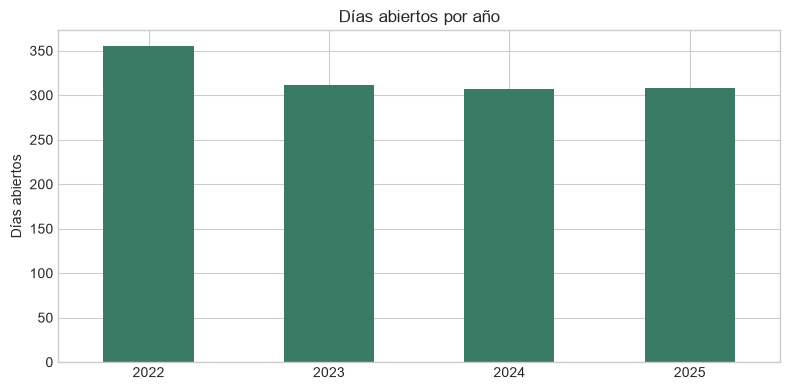

Conclusión: entre 2022 y 2025, el número de días abiertos cambió en -47 días. Esto puede influir en la facturación anual.


In [6]:
ax = anual["dias_abiertos"].plot.bar(figsize=(8, 4), color="#397b65", title="Días abiertos por año")
ax.set(xlabel="", ylabel="Días abiertos")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

primer_anio, ultimo_anio = anual.index.min(), anual.index.max()
diferencia = int(anual.loc[ultimo_anio, "dias_abiertos"] - anual.loc[primer_anio, "dias_abiertos"])
print(f"Conclusión: entre {primer_anio} y {ultimo_anio}, el número de días abiertos cambió en {diferencia:+d} días. Esto puede influir en la facturación anual.")

In [ ]:
ax = anual[["media_dia_natural_eur", "media_dia_abierto_eur"]].plot.bar(
    figsize=(8, 4), color=["#397b65", "#ce8754"], title="Venta media diaria (privado)"
)
ax.set(xlabel="", ylabel="Euros (privado)")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Día natural", "Día abierto"])
plt.tight_layout()
plt.show()

print("Conclusión privada: la media por día natural incluye cierres; la media por día abierto permite comparar la actividad cuando la tienda abre.")

## 4. Evolución con base 2022

Se muestran dos indicadores distintos: la facturación mensual total comparada con el mes medio de 2022, y la venta media por día abierto de cada mes comparada con la media de todos los días abiertos de 2022. Cada referencia vale 100. El primer indicador refleja la facturación del canal y el segundo permite comparar la actividad cuando la tienda abre. Un mes sin aperturas no tiene media por día abierto ni índice de esa media.

La evolución relativa también es información real. Un índice no garantiza confidencialidad, y conocer la base en euros permitiría recuperar los importes.

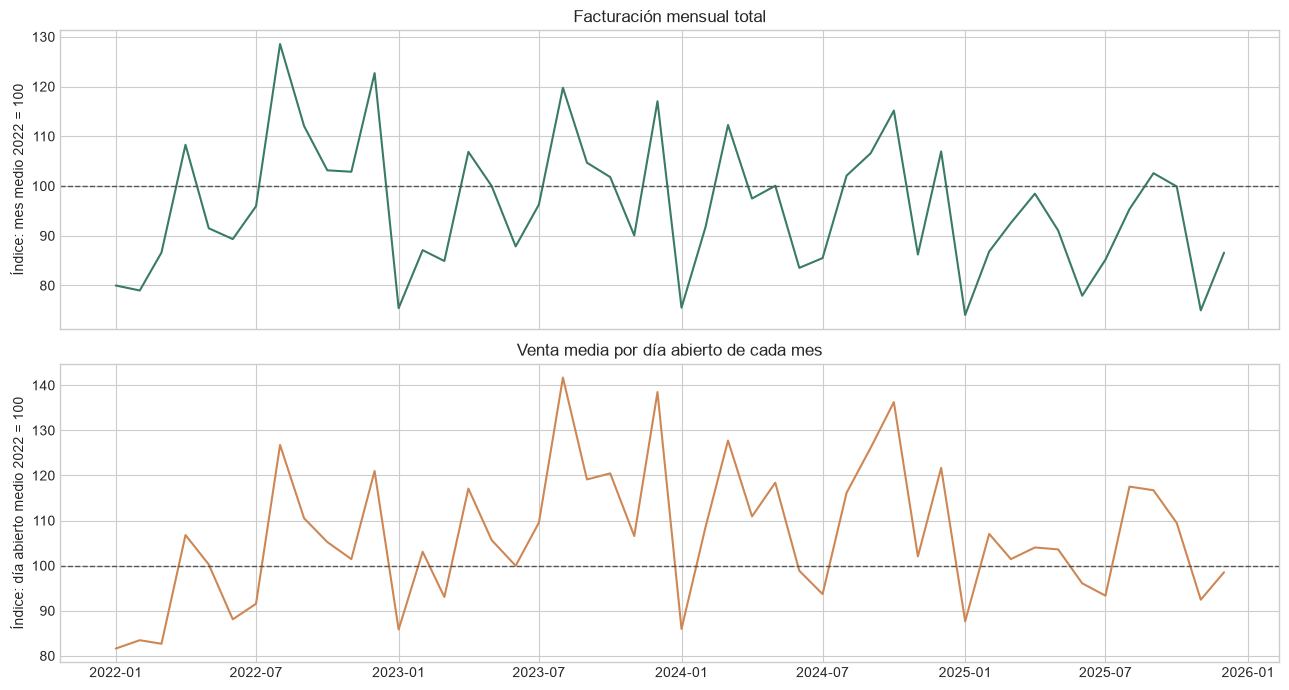

,indice_total_mensual_2022,indice_dia_abierto_2022,dias_abiertos,dias_naturales
periodo,,,,
2022-01,80.0,81.6,29,31
2022-02,79.0,83.5,28,28
2022-03,86.6,82.7,31,31
2022-04,108.3,106.8,30,30
2022-05,91.5,100.3,27,31
2022-06,89.3,88.1,30,30
2022-07,95.9,91.5,31,31
2022-08,128.5,126.8,30,31
2022-09,112.1,110.5,30,30


In [8]:
mensual = ventas.groupby("periodo").agg(
    ventas_eur=("total", "sum"),
    dias_abiertos=("abierto", "sum"),
    dias_naturales=("fecha", "size"),
)
mensual["anio"] = mensual.index.year
mensual["mes"] = mensual.index.month
mensual["media_dia_abierto_eur"] = mensual["ventas_eur"].div(
    mensual["dias_abiertos"].replace(0, np.nan)
)
base_mensual_2022 = mensual.loc[mensual["anio"].eq(2022), "ventas_eur"].mean()
base_abierto_2022 = ventas.loc[ventas["anio"].eq(2022) & ventas["abierto"], "total"].mean()
if pd.isna(base_mensual_2022) or base_mensual_2022 <= 0:
    raise ValueError("La venta mensual media de 2022 debe ser positiva para calcular el índice.")
if pd.isna(base_abierto_2022) or base_abierto_2022 <= 0:
    raise ValueError("La venta media por día abierto de 2022 debe ser positiva para calcular el índice.")
mensual["indice_total_mensual_2022"] = mensual["ventas_eur"].div(base_mensual_2022).mul(100)
mensual["indice_dia_abierto_2022"] = mensual["media_dia_abierto_eur"].div(base_abierto_2022).mul(100)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(mensual.index.to_timestamp(), mensual["indice_total_mensual_2022"], color="#397b65")
axes[0].set(title="Facturación mensual total", ylabel="Índice: mes medio 2022 = 100")
axes[1].plot(mensual.index.to_timestamp(), mensual["indice_dia_abierto_2022"], color="#ce8754")
axes[1].set(title="Venta media por día abierto de cada mes", ylabel="Índice: día abierto medio 2022 = 100", xlabel="")
for axis in axes:
    axis.axhline(100, color="#555555", linestyle="--", linewidth=1)
fig.tight_layout()
plt.show()

display(mensual[["indice_total_mensual_2022", "indice_dia_abierto_2022", "dias_abiertos", "dias_naturales"]].round(1))

In [9]:
primero, ultimo = mensual.iloc[0], mensual.iloc[-1]
print("Conclusión del gráfico y tabla mensual:")
for columna, nombre in [("indice_total_mensual_2022", "facturación mensual"), ("indice_dia_abierto_2022", "venta media por día abierto")]:
    if pd.notna(primero[columna]) and pd.notna(ultimo[columna]) and primero[columna] > 0:
        variacion = (ultimo[columna] / primero[columna] - 1) * 100
        print(f"La {nombre} del último mes varió un {variacion:+.1f} % respecto al primer mes. La comparación de dos meses puede estar afectada por estacionalidad; no resume por sí sola la tendencia.")
    else:
        print(f"No se puede comparar la {nombre} entre los meses extremos por falta de una base positiva.")
print("El índice de facturación y el de venta por día abierto usan referencias distintas, ambas basadas en 2022.")

Conclusión del gráfico y tabla mensual:
La facturación mensual del último mes varió un +8.2 % respecto al primer mes. La comparación de dos meses puede estar afectada por estacionalidad; no resume por sí sola la tendencia.
La venta media por día abierto del último mes varió un +20.7 % respecto al primer mes. La comparación de dos meses puede estar afectada por estacionalidad; no resume por sí sola la tendencia.
El índice de facturación y el de venta por día abierto usan referencias distintas, ambas basadas en 2022.


## 5. Estacionalidad y calendario

Las medias y sus índices consideran únicamente días abiertos, con la venta media por día abierto de 2022 como referencia de 100. Se incluyen también los recuentos de días naturales y abiertos para contextualizar cambios en las aperturas. Los grupos sin días abiertos no tienen índice.

La comparación de festivos y fines de semana es descriptiva: pueden influir las diferencias de día de la semana, temporada, horario, eventos u otros factores. No demuestra un efecto causal.

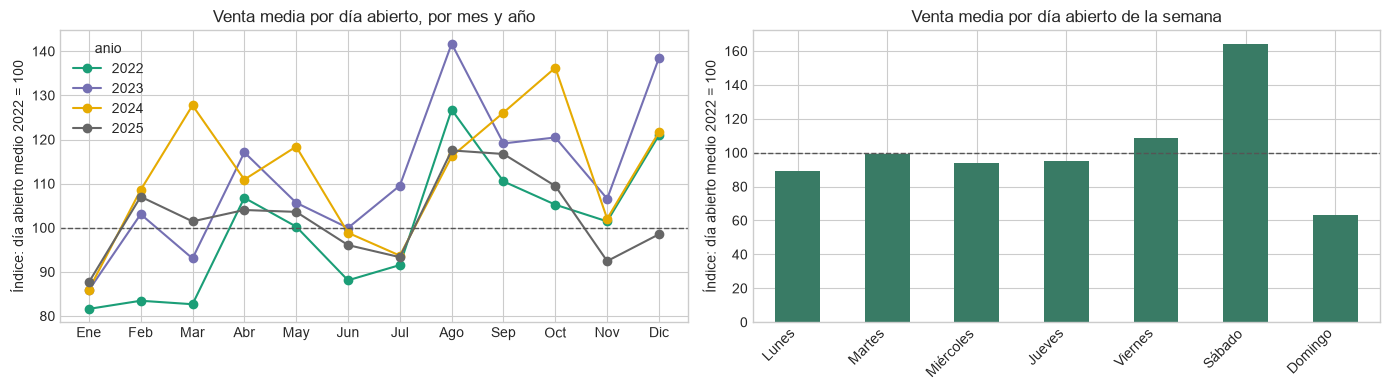

,observaciones,dias_abiertos,indice_media_dia_abierto,apertura_pct
dia_semana_num,,,,
Lunes,209,199,89.0,95.2
Martes,209,206,99.3,98.6
Miércoles,209,204,94.0,97.6
Jueves,208,202,94.9,97.1
Viernes,208,202,108.9,97.1
Sábado,209,205,163.9,98.1
Domingo,209,63,63.2,30.1


In [10]:
abiertos_calendario = ventas.loc[ventas["abierto"]]
base_abierto_2022 = abiertos_calendario.loc[abiertos_calendario["anio"].eq(2022), "total"].mean()
if pd.isna(base_abierto_2022) or base_abierto_2022 <= 0:
    raise ValueError("La venta media por día abierto de 2022 debe ser positiva para calcular el índice.")
por_mes = abiertos_calendario.groupby(["anio", "mes"])["total"].mean().unstack("anio").div(base_abierto_2022).mul(100)
por_dia = ventas.groupby("dia_semana_num").agg(
    observaciones=("fecha", "size"),
    dias_abiertos=("abierto", "sum"),
    ventas_eur=("total", "sum"),
)
por_dia["indice_media_dia_abierto"] = por_dia["ventas_eur"].div(
    por_dia["dias_abiertos"].replace(0, np.nan)
).div(base_abierto_2022).mul(100)
por_dia["apertura_pct"] = por_dia["dias_abiertos"].div(por_dia["observaciones"]).mul(100)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_mes.plot(ax=axes[0], marker="o", colormap="Dark2")
axes[0].set_xticks(range(1, 13), meses)
axes[0].set(title="Venta media por día abierto, por mes y año", xlabel="", ylabel="Índice: día abierto medio 2022 = 100")
por_dia["indice_media_dia_abierto"].plot.bar(ax=axes[1], color="#397b65")
axes[1].set_xticks(range(7), dias, rotation=45, ha="right")
axes[1].set(title="Venta media por día abierto de la semana", xlabel="", ylabel="Índice: día abierto medio 2022 = 100")
for axis in axes:
    axis.axhline(100, color="#555555", linestyle="--", linewidth=1)
fig.tight_layout()
plt.show()
display(por_dia.drop(columns="ventas_eur").rename(index=dict(enumerate(dias))).round(1))

In [11]:
print("Conclusión del gráfico mensual por años:")
por_mes_global = abiertos_calendario.groupby("mes")["total"].agg(["mean", "size"])
mes_maximo = int(por_mes_global["mean"].idxmax())
mes_minimo = int(por_mes_global["mean"].idxmin())
print(f"En el conjunto de años, {meses[mes_maximo - 1]} presenta la mayor media por día abierto y {meses[mes_minimo - 1]} la menor. La composición de años y aperturas puede influir en esta comparación.")
print("Conclusión del gráfico y tabla por día de semana:")
indices_semana = por_dia["indice_media_dia_abierto"].dropna()
if indices_semana.empty:
    print("No hay días abiertos suficientes para comparar los días de la semana.")
else:
    dia_maximo = int(indices_semana.idxmax())
    dia_minimo = int(indices_semana.idxmin())
    print(f"La mayor media corresponde a {dias[dia_maximo]} y la menor a {dias[dia_minimo]}, considerando solo días abiertos. Los recuentos indican cuántas aperturas sustentan cada media.")

Conclusión del gráfico mensual por años:
En el conjunto de años, Ago presenta la mayor media por día abierto y Ene la menor. La composición de años y aperturas puede influir en esta comparación.
Conclusión del gráfico y tabla por día de semana:
La mayor media corresponde a Sábado y la menor a Domingo, considerando solo días abiertos. Los recuentos indican cuántas aperturas sustentan cada media.


In [12]:
def resumen_calendario(data, variable):
    summary = data.groupby(variable).agg(
        observaciones=("fecha", "size"),
        dias_abiertos=("abierto", "sum"),
        ventas_eur=("total", "sum"),
    )
    summary["apertura_pct"] = summary["dias_abiertos"].div(summary["observaciones"]).mul(100)
    summary["indice_dia_abierto_2022"] = summary["ventas_eur"].div(
        summary["dias_abiertos"].replace(0, np.nan)
    ).div(base_abierto_2022).mul(100)
    return summary.drop(columns="ventas_eur").round(1)

print("Comparación descriptiva de festivos (0: no, 1: sí)")
display(resumen_calendario(ventas, "es_festivo"))
print("Comparación descriptiva de fines de semana (False: no, True: sí)")
display(resumen_calendario(ventas, "fin_semana"))

Comparación descriptiva de festivos (0: no, 1: sí)


,observaciones,dias_abiertos,apertura_pct,indice_dia_abierto_2022
es_festivo,,,,
0,1403,1251,89.2,106.7
1,58,30,51.7,86.8


Comparación descriptiva de fines de semana (False: no, True: sí)


,observaciones,dias_abiertos,apertura_pct,indice_dia_abierto_2022
fin_semana,,,,
False,1043,1013,97.1,97.2
True,418,268,64.1,140.3


In [13]:
for variable, etiqueta in [("es_festivo", "festivos"), ("fin_semana", "fines de semana")]:
    medias = ventas.loc[ventas["abierto"]].groupby(variable)["total"].mean()
    no_marcado, marcado = (False, True) if variable == "fin_semana" else (0, 1)
    if no_marcado in medias.index and marcado in medias.index and medias.loc[no_marcado] > 0:
        diferencia = (medias.loc[marcado] / medias.loc[no_marcado] - 1) * 100
        print(f"Conclusión de la tabla de {etiqueta}: entre los días abiertos, el grupo marcado presenta una media {diferencia:+.1f} % respecto al no marcado. Es una asociación, no una prueba causal.")
    else:
        print(f"Conclusión de la tabla de {etiqueta}: no hay una base válida de días abiertos para comparar ambos grupos.")

Conclusión de la tabla de festivos: entre los días abiertos, el grupo marcado presenta una media -18.6 % respecto al no marcado. Es una asociación, no una prueba causal.
Conclusión de la tabla de fines de semana: entre los días abiertos, el grupo marcado presenta una media +44.2 % respecto al no marcado. Es una asociación, no una prueba causal.


## 6. Reparto entre tarjeta y efectivo

El porcentaje de cada periodo se calcula como importe acumulado del medio de pago dividido entre el total acumulado; no es la media simple de los porcentajes diarios. Los días sin ventas no tienen porcentaje diario definido. El reparto es información derivada real y debe revisarse antes de publicarse.

,Tarjeta (%),Efectivo (%)
anio,,
2022,50.5,49.5
2023,54.1,45.9
2024,57.4,42.6
2025,59.9,40.1


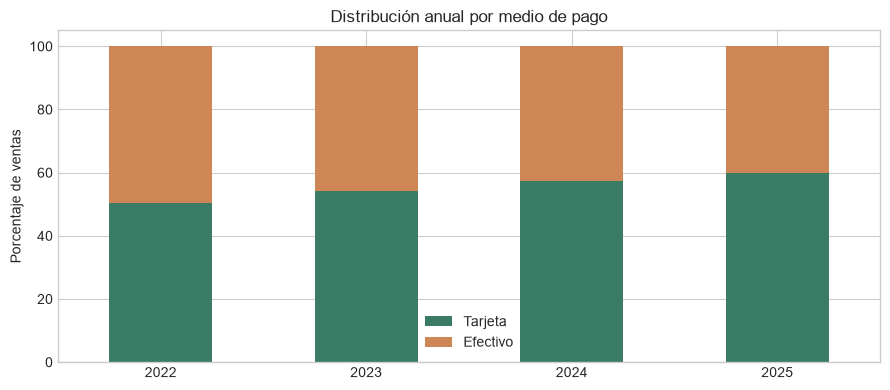

In [14]:
pagos_anuales = ventas.groupby("anio")[["tarjeta", "efectivo", "total"]].sum()
pagos_pct = pagos_anuales[["tarjeta", "efectivo"]].div(pagos_anuales["total"].where(pagos_anuales["total"].gt(0)), axis=0).mul(100)
display(pagos_pct.rename(columns={"tarjeta": "Tarjeta (%)", "efectivo": "Efectivo (%)"}).round(1))

ax = pagos_pct.plot.bar(stacked=True, color=["#397b65", "#ce8754"], figsize=(9, 4))
ax.set(title="Distribución anual por medio de pago", xlabel="", ylabel="Porcentaje de ventas")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Tarjeta", "Efectivo"])
plt.tight_layout()
plt.show()

In [15]:
print("Conclusión del gráfico y tabla de pagos:")
primer_anio_pagos, ultimo_anio_pagos = pagos_pct.index.min(), pagos_pct.index.max()
primer_porcentaje = pagos_pct.loc[primer_anio_pagos, "tarjeta"]
ultimo_porcentaje = pagos_pct.loc[ultimo_anio_pagos, "tarjeta"]
if pd.notna(primer_porcentaje) and pd.notna(ultimo_porcentaje):
    variacion_puntos = ultimo_porcentaje - primer_porcentaje
    print(f"La proporción de ventas con tarjeta cambió {variacion_puntos:+.1f} puntos porcentuales entre {primer_anio_pagos} y {ultimo_anio_pagos}. El cálculo pondera cada día por su facturación.")
else:
    print("No se puede comparar la proporción de tarjeta por falta de ventas en uno de los años.")

Conclusión del gráfico y tabla de pagos:
La proporción de ventas con tarjeta cambió +9.5 puntos porcentuales entre 2022 y 2025. El cálculo pondera cada día por su facturación.


## 7. Días de ventas excepcionalmente altas o bajas

**Vista privada en euros y fechas concretas.** Para explorar días abiertos alejados de la distribución habitual se calcula el rango intercuartílico (IQR = Q3 - Q1). Se señalan los días por debajo de Q1 - 1,5 × IQR o por encima de Q3 + 1,5 × IQR. No es una comparación con la media ni un umbral de negocio.

Estos días pueden ser ventas válidas, por ejemplo durante festivos, puentes o ferias; la regla no identifica su causa y no supone que sean errores. Se muestran todos los días señalados para contrastarlos con la bodega. No se elimina ni modifica ningún registro.

In [ ]:
abiertos = ventas.loc[ventas["abierto"]].copy()
if abiertos.empty:
    print("No hay días abiertos para evaluar ventas excepcionalmente altas o bajas.")
else:
    q1 = abiertos["total"].quantile(0.25)
    q3 = abiertos["total"].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    dias_excepcionales = abiertos.loc[
        abiertos["total"].lt(limite_inferior) | abiertos["total"].gt(limite_superior),
        ["fecha", "tarjeta", "efectivo", "total", "es_festivo", "fin_semana"],
    ].copy()
    dias_excepcionales["tipo"] = np.where(
        dias_excepcionales["total"].gt(limite_superior), "Venta alta", "Venta baja"
    )
    dias_excepcionales = dias_excepcionales.sort_values("fecha")
    print(f"Días abiertos señalados para exploración: {len(dias_excepcionales)}")
    print(f"Ventas altas: {dias_excepcionales['tipo'].eq('Venta alta').sum()}; ventas bajas: {dias_excepcionales['tipo'].eq('Venta baja').sum()}")
    with pd.option_context("display.max_rows", None):
        display(dias_excepcionales)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.boxplot(abiertos["total"], vert=False)
    ax.set(title="Distribución de ventas en días abiertos", xlabel="Euros (privado)")
    fig.tight_layout()
    plt.show()

In [17]:
print("Conclusión de la tabla y el gráfico de días excepcionales:")
if abiertos.empty:
    print("No hay días abiertos para evaluar la distribución.")
elif dias_excepcionales.empty:
    print("La regla IQR no señaló días para exploración. Esto no demuestra que todos los registros sean correctos.")
else:
    altas = int(dias_excepcionales["tipo"].eq("Venta alta").sum())
    bajas = int(dias_excepcionales["tipo"].eq("Venta baja").sum())
    festivos = int(dias_excepcionales["es_festivo"].eq(1).sum())
    print(f"La regla IQR señaló {altas} días de venta alta y {bajas} de venta baja; {festivos} coinciden con festivos registrados. Pueden ser ventas válidas y el calendario por sí solo no explica su causa.")

Conclusión de la tabla y el gráfico de días excepcionales:
La regla IQR señaló 29 días de venta alta y 0 de venta baja; 1 coinciden con festivos registrados. Pueden ser ventas válidas y el calendario por sí solo no explica su causa.


In [21]:
dias_excepcionales["fecha"].dt.day_name().value_counts()

fecha
Saturday     21
Friday        2
Monday        2
Tuesday       1
Thursday      1
Wednesday     1
Sunday        1
Name: count, dtype: int64

## 8. Interpretación y preparación del modelo

### Lectura del histórico 2022-2025

En el Gold analizado, entre 2022 y 2025 la facturación anual disminuyó un 11,2 %, mientras que la venta media por día abierto aumentó un 2,3 % y hubo 47 días abiertos menos. La reducción de aperturas es relevante para interpretar la caída de la facturación, aunque estos datos no explican sus causas.

En el conjunto de los cuatro años, agosto presenta la mayor venta media por día abierto y enero la menor. Por día de semana, la mayor media corresponde al sábado y la menor al domingo; conviene considerar los recuentos de aperturas antes de generalizar. Entre días abiertos, la media en festivos fue un 18,6 % inferior a la de días no festivos y la de fines de semana un 44,2 % superior a la de lunes a viernes. Son comparaciones descriptivas: los grupos pueden diferir en temporada, horario y otros factores.

El peso de la tarjeta aumentó 9,5 puntos porcentuales entre 2022 y 2025. El criterio IQR identificó 29 días de ventas altas y ninguno de ventas bajas; uno coincide con un festivo registrado. Pueden ser ventas válidas y no se descartan. El dataset no identifica ferias ni puentes, por lo que no se puede atribuirles esas ventas sin información adicional.

Esta lectura es una instantánea del Gold actual; si los datos cambian, hay que actualizarla. Describe lo observado, pero no determina si conviene cerrar el canal, ya que no mide la rentabilidad ni su contribución frente a otros canales. Las conclusiones calculadas en la siguiente celda permiten contrastar las variaciones al volver a ejecutar el notebook.

### Preparación del modelo

Define primero qué se predice y con qué horizonte. Se recomienda separar entrenamiento y evaluación en orden temporal y comparar el modelo con una referencia sencilla. Usa solo información disponible en el momento de predecir: los porcentajes de pago y la apertura deducida de las ventas del mismo día no se conocen de antemano. El calendario de apertura previsto sí podría utilizarse si estuviera disponible de forma fiable.

**Antes de publicar:** borra las salidas que contengan importes en euros, fechas o detalles confidenciales; revisa también las celdas Markdown y código. Los índices, porcentajes y tendencias reales solo se comparten dentro de lo autorizado. El Gold real, los informes y modelos entrenados permanecen privados.

In [18]:
print("Síntesis del EDA:")
primer_anio, ultimo_anio = anual.index.min(), anual.index.max()
for columna, descripcion in [("ventas_totales_eur", "facturación total"), ("media_dia_abierto_eur", "venta media por día abierto")]:
    inicial = anual.loc[primer_anio, columna]
    final = anual.loc[ultimo_anio, columna]
    if pd.notna(inicial) and pd.notna(final) and inicial > 0:
        print(f"- La {descripcion} varió un {(final / inicial - 1) * 100:+.1f} % entre {primer_anio} y {ultimo_anio}.")
    else:
        print(f"- No hay una base válida para comparar la {descripcion} entre los años extremos.")
variacion_aperturas = int(anual.loc[ultimo_anio, "dias_abiertos"] - anual.loc[primer_anio, "dias_abiertos"])
print(f"- El número de días abiertos cambió en {variacion_aperturas:+d} días entre esos años; conviene considerar conjuntamente actividad y aperturas.")
if pd.notna(primer_porcentaje) and pd.notna(ultimo_porcentaje):
    print(f"- El peso de la tarjeta cambió {ultimo_porcentaje - primer_porcentaje:+.1f} puntos porcentuales entre {primer_anio_pagos} y {ultimo_anio_pagos}.")
if not abiertos.empty:
    print(f"- La regla IQR señaló {len(dias_excepcionales)} días abiertos para exploración, no para eliminación automática.")
print("- Las diferencias por festivo, fin de semana y estación son descriptivas; pueden intervenir otros factores no registrados.")
print("- El análisis de ventas no mide la rentabilidad ni la contribución relativa frente a otros canales. La decisión empresarial requiere información adicional.")

Síntesis del EDA:
- La facturación total varió un -11.2 % entre 2022 y 2025.
- La venta media por día abierto varió un +2.3 % entre 2022 y 2025.
- El número de días abiertos cambió en -47 días entre esos años; conviene considerar conjuntamente actividad y aperturas.
- El peso de la tarjeta cambió +9.5 puntos porcentuales entre 2022 y 2025.
- La regla IQR señaló 29 días abiertos para exploración, no para eliminación automática.
- Las diferencias por festivo, fin de semana y estación son descriptivas; pueden intervenir otros factores no registrados.
- El análisis de ventas no mide la rentabilidad ni la contribución relativa frente a otros canales. La decisión empresarial requiere información adicional.
